# Lab09: User Stories Generation, ROC Curve and Router design

## Task 1 - User Stories Generation

User stories are brief, simple descriptions of a feature or requirement from the perspective of an end user. They are used in Agile software development to capture the user’s needs and goals in a way that prioritizes functionality and value. A typical user story follows the format:

"As a [type of user], I want [a specific goal] so that [reason or benefit]."

This format ensures the focus stays on delivering solutions that meet the user’s expectations. User stories guide development by defining clear, actionable tasks for teams while remaining flexible and open to adaptation as the project evolves.

Our objective is to create an agent architecture like the following one:

1. **Problem Specification (Domain Specification):**
The process begins with the definition of a problem description, which outlines the domain or context of the system. This serves as the input to the LLM and sets the foundation for generating user stories. Our problem specification is provided as the input to the process.

2. **Role(s) Extraction ("Who" Aspect):**
A prompt is used to extract roles from the problem description.
Roles represent the different types of users or stakeholders involved in the system This step answers "who" the user stories are about.

3. **Function(s) Extraction ("What" Aspect):**
Another prompt is used to extract functions associated with each role.
Functions describe the specific actions or goals the roles aim to perform within the system. This step answers "what" the users want to achieve.

4. **Purpose(s) Extraction ("Why" Aspect):**
A subsequent prompt is used to determine the purposes behind the functions identified. Purposes explain the reasons or motivations behind the desired actions of the roles. This step answers "why" the users need the functions.

5. **User Stories Generation:**
Combining the roles (who), functions (what), and purposes (why), a final prompt generates complete user stories. These user stories take the standard Agile format: "As a \<who\>, I want \<what\>, so that \<why\>."

**Feedback Loop and Prompt Chain**:
The process is iterative, as each step informs the next and ensures that the roles, functions, and purposes are fully aligned. The LLM is guided by a structured "prompt chain," where prompts are carefully designed to extract specific information at each stage.

**Output**:
The final output consists of a set of user stories that capture the needs and goals of the system's users in a concise, actionable format. These stories guide development teams in implementing the desired features and functionalities.





In [ ]:
# ------------------ Initial setup ---------------------

import torch

# Detect the device available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device: ",
      device)  # You may need to execute "pip install torch --index-url https://download.pytorch.org/whl/cu124" (or other versions in place of the 12.4) in order to use the GPU

# HuggingFace login: it is needed only once

#----------------Google Colab only---------------------
# from huggingface_hub import login
#from google.colab import userdata
#login(userdata.get('HF_TOKEN'))
#----------------Google Colab only---------------------

#----------------Local Runtime only---------------------
import os
from dotenv import load_dotenv  # pip install python-dotenv
from huggingface_hub import login

load_dotenv()
hf_token = os.getenv("HF_TOKEN")  # Create this constant in the file .env (put it in the root dir of your project)
login(token=hf_token)
#----------------Local Runtime only---------------------

In [ ]:
from transformers import AutoTokenizer
# These functions are adapted from the previous Lab.
from transformers import BitsAndBytesConfig  # pip install bitsandbytes

from transformers import (
    AutoModelForCausalLM,
    GenerationConfig,
    pipeline,
    TextGenerationPipeline,
)


def load_model(model_id: str, quantization: bool = False) -> TextGenerationPipeline:
    """Loads a pretrained causal language model and builds a configured text-generation pipeline.

    Note: The initial execution may take significant time to download the model weights.

    Args:
        model_id (str): The Hugging Face model identifier or local path.
        quantization (bool, optional): Whether to use quantization. Defaults to False.

    Returns:
        TextGenerationPipeline: A Hugging Face text-generation pipeline initialized with
            the float16 causal LM, its tokenizer, and custom generation configuration.
    """
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.float16
    )
    if quantization:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float16, device_map="auto",
                                                     quantization_config=quantization_config)
    else:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float16, device_map="auto", )
    tokenizer = AutoTokenizer.from_pretrained(model_id, clean_up_tokenization_spaces=False)

    # Configure generation parameters
    gen_config = GenerationConfig.from_model_config(model.config)
    #gen_config.temperature = 0.1              # Regulate randomness, use with do_sample = True
    # gen_config.max_length = None              # Since max_new_tokens is already set
    #gen_config.repetition_penalty = 2.0  # Penalize repetition
    gen_config.no_repeat_ngram_size = 3  # Avoid repeating trigrams
    gen_config.do_sample = False  # Set to False in order to use Greedy or Beam search
    gen_config.num_beams = 3  # Use with do_sample = False
    gen_config.eos_token_id = tokenizer.eos_token_id  # End generation at EOS token
    gen_config.pad_token_id = tokenizer.pad_token_id
    gen_config.early_stopping = True

    model.generation_config = gen_config

    text_generation_pipeline = pipeline(
        "text-generation",
        model=model,
        tokenizer=tokenizer,
    )

    return text_generation_pipeline

## Usage example:
# text_generation_pipeline = load_model("causal-language-model")
# messages = [...]
# outputs = text_generation_pipeline(messages, max_new_tokens = 200)
# print(outputs[0]["generated_text"][-1]["content"])

In [ ]:
# Reference requirements_text

requirements_text = "The proposed platform is designed to enhance the hiking experience for various user groups, including visitors, local guides, platform managers, and hut workers. The platform provides a centralized repository of hiking routes, hut information, and parking facilities. It also enables interactive features such as real-time hike tracking, personalized recommendations, and group hike planning. By combining these capabilities, the platform seeks to foster safe, informed, and collaborative hiking experiences.\
The platform will be deployed as a cloud-based web and mobile application accessible to all stakeholders. The distribution strategy includes an app available on major mobile operating systems, such as iOS and Android, alongside a responsive web interface. It will require an internet connection for features like real-time tracking, notifications, and user authentication, though some offline capabilities, such as pre-downloaded hike information, will also be available.\
User authentication will be role-based, ensuring that only authorized users, such as verified hut workers and platform managers, can access sensitive or administrative features.\
Visitors are the primary users of the platform. They can browse a comprehensive list of hiking trails, filter them based on specific criteria such as difficulty, length, or starting point, and view detailed descriptions. To access advanced features like personalized recommendations, visitors can create user accounts by registering on the platform. Registered users can record their fitness parameters, enabling the system to suggest trails tailored to their capabilities.\
During a hike, visitors can record their progress by marking reference points and sharing their live location through a broadcasting URL. They can also initiate group activities by planning hikes, adding group members, and confirming group participation. The platform allows visitors to start, terminate, and track their hikes, with notifications for unfinished hikes or late group members to ensure safety and accountability.\
Local guides enrich the platform by contributing essential information. They can add detailed descriptions of hikes, parking facilities, and huts, ensuring hikers have accurate and comprehensive data. Local guides also link parking lots and huts to specific trails as starting or arrival points, enhancing the planning process.\
To aid in the visual representation and accessibility of information, local guides can upload pictures of huts and connect these locations directly to hikes. This integration simplifies route planning and helps visitors visualize their journey.\
Platform managers oversee the operational integrity and safety of the platform. They verify new hut worker registrations, ensuring that only authorized personnel can update hut-related data. Managers can also broadcast weather alerts for specific areas, notifying all hikers in those regions through push notifications. This ensures that users stay informed about potentially hazardous conditions.\
The platform manager's role includes maintaining an organized and secure user system while facilitating collaboration between local guides, hut workers, and visitors.\
Hut workers are critical to the maintenance of up-to-date trail and accommodation information. After registering and being verified, hut workers can log into the platform to add or update information about their assigned huts, including uploading pictures and describing the facilities available. They can also monitor and report on the condition of nearby trails, ensuring hikers receive current information.\
Hut workers play a vital role in providing situational updates for hikers. For instance, if a nearby trail is impacted by severe weather or physical obstructions, they can communicate these conditions through the platform. This enhances the safety and preparedness of all hikers relying on the platform."

## Extracting the Actors

To automate the extraction of roles ("Who" aspect) from a problem description, we utilize a language model (LLM) to identify key actors or stakeholders involved in the system. Roles, such as "visitors," "local guides," "platform managers," and "hut workers," represent the primary users or contributors to the system and are essential for generating accurate and actionable user stories. This step focuses on using the LLM to extract these roles and then validating the quality of the extraction by comparing the results against a reference dataset.

The LLM is provided with a detailed problem description and prompted to extract the roles (actors) associated with the system. The prompt should be carefully designed to ensure the LLM captures **all** relevant roles based on the context of the problem.







In [ ]:
# Define three different prompts for extracting users, using the zero-shot, one-shot and few-shot approaches sequentially. Then, evaluate the differences in terms of output format and actual results

# IMPORTANT: whether you use the chat template or not, remember to add the shots into the correct structure composed by user's query and assistant's response (see previous labs)

query = "Now, extract the roles from the following requirements text:"

shots = [  # This is a list of lists, useful to separate each shot from each other

    # First shot
    [
        {'role': 'user',
         'content': """Requirements Text:
"The application is designed to streamline food delivery operations. Customers can browse menus and place orders. Delivery personnel use the app to view delivery assignments and update order statuses. Restaurant managers can manage their menus and track incoming orders."""},
        {'role': 'assistant', 'content': """1. Customers
2. Delivery Personnel
3. Restaurant Managers"""},
    ],

    # Second shot
    [
        {'role': 'user',
         'content': """Requirements Text:
The platform supports the education sector by providing tools for students, teachers, and administrators. Students can access course materials, submit assignments, and track their progress. Teachers can create content, grade submissions, and communicate with students. Administrators oversee user registrations and system performance."""},
        {'role': 'assistant',
         'content': """1. Students
2. Teachers
3. Administrators"""}
    ],

    # Third shot
    [
        {'role': 'user',
         'content': """Requirements Text:
The system provides real-time updates for commuters, transit operators, and city planners. Commuters can check schedules and delays. Transit operators monitor vehicle statuses and manage timetables. City planners analyze system data to improve routes and infrastructure."""},
        {'role': 'assistant',
         'content': """1. Commuters
2. Transit Operators
3. City Planners"""}
    ]
]

system_prompt = """""" # TODO: specify a persona for the LLM, declare its task, and the expected output format

# Build the message list for each prompting technique

messages_zero_shot = [
    {'role': 'system', 'content': system_prompt},
    {'role': 'user', 'content': f"{query}\n\nRequirements Text:\n{requirements_text}"}
]

messages_one_shot = [
    # TODO
]

messages_few_shots = [
    # TODO
]

text_generation_pipeline = load_model("meta-llama/Llama-3.2-3B-Instruct")

# Call the LLM function for the three prompts and print the results
roles_extracted_zero_shot = "" # TODO

print("\n\nExtracted Roles - zero shot: \n", roles_extracted_zero_shot)

roles_extracted_one_shot = "" # TODO

print("\n\nExtracted Roles - one shot: \n", roles_extracted_one_shot)

roles_extracted_few_shot = "" # TODO

print("\n\nExtracted Roles - few shot: \n", roles_extracted_few_shot)

We validate the extracted roles against a reference dataset contained in a CSV file named stories.csv. This file includes a specific column listing all the predefined roles associated with the system. These roles serve as the ground truth for validation purposes.


To assess the accuracy and completeness of the LLM’s role extraction, we compute the precision and recall metrics by comparing the LLM's output to the ground truth roles:

- **Precision**: Measures how many of the roles extracted by the LLM are correct (i.e., exist in the reference dataset).

  $P = \frac{True\ Positives}{True\ Positives + False\ Positives}$


- **Recall**: Measures how many of the ground truth roles were successfully identified by the LLM.

  $R = \frac{True\ Positives}{True\ Positives + False\ Negatives}$


After extracting the roles using the LLM, the results are compared to the roles in the reference column from the CSV file. For each role identified by the LLM:

- If the role exists in the reference dataset, it is considered a true positive.
- If the role does not exist in the reference dataset, it is marked as a false positive.
- Any role in the reference dataset that the LLM fails to identify is considered a false negative.

The final output of this process includes:
- A list of roles extracted by the LLM.
- Precision and recall metrics, which provide a quantitative assessment of the LLM’s performance in role extraction.

In [ ]:
import csv
import re


#define a function to extract unique roles from the .csv files containing user stories

def extract_unique_roles(_file_path: str):
    roles = set()  # Use a set to ensure roles are unique
    role_pattern = r"As a(n)? ([^I]+)"  # Regex to match the role in the user story

    with open(_file_path, 'r', encoding='utf-8') as csvfile:
        reader = csv.reader(csvfile)
        next(reader)  # Skip the header row
        for row in reader:
            if len(row) > 4:  # Ensure the row has enough fields
                description = row[4]
                _match = re.search(role_pattern, description)
                if _match:
                    role = _match.group(2).strip()
                    roles.add(role)

    return list(roles)


def normalize_roles(role_list: list[str]) -> list[str]:
    """
    Takes a list of roles, makes all the texts lower case, removes spaces, and removes the 's' at the end (plural).
    """
    return [r.lower().strip().rstrip('s') for r in role_list]


# find the unique roles and put them into a list
file_path = 'stories.csv'
groundtruth_roles = extract_unique_roles(file_path)
print("EXPECTED ROLES: ", groundtruth_roles)  #EXPECTED RESULT FOR ROLES

#now extract unique roles from the result provided by the LLM
#for simplicity, we only consider the few shots prompt for this purpose

actual_roles = "" # TODO write the code to obtain a list of strings from the variable "roles_extracted_few_shot"

print("ACTUAL ROLES: ", actual_roles)  #ACTUAL RESULT FOR ROLES


def evaluate_actors(_actual_roles: list[str], _groundtruth_roles: list[str]) -> tuple[float, float]:
    #Compute precision and recall
    #use the normalized roles, i.e., don't consider spaces and 's' at the end of the roles

    normalized_actual_set = set(normalize_roles(_actual_roles))
    normalized_expected_set = set(normalize_roles(_groundtruth_roles))

    #TODO use the operators on sets
    _true_positives = ""
    _false_positives = ""
    _false_negatives = ""

    print("True Positives:", _true_positives)
    print("False Positives:", _false_positives)
    print("False Negatives:", _false_negatives)

    # TODO use the number of elements in the three sets already defined in order to compute precision and recall
    prec = ""
    rec = ""

    return prec, rec


precision, recall = evaluate_actors(_actual_roles=actual_roles, _groundtruth_roles=groundtruth_roles)
print("\n\nPrecision:", precision)
print("Recall:", recall)


## Extracting the Functions

In this step, the primary goal is to automate the identification of functions required by the roles identified in the previous step (Role Extraction). The function refers to the tasks or actions that the roles need to perform within the system. To achieve this, a language model (LLM) is used to analyze the problem description, and based on the roles identified, it is prompted to extract the functions those roles desire to perform.

For example, after identifying the role of "visitors" or "local guides," the LLM is prompted to determine the specific actions these roles want to carry out within the system, such as "view hikes," "add descriptions," or "manage registrations." This extraction process is critical for understanding the functionality needed in the system to meet the requirements of its stakeholders.

The extracted functions are validated to ensure completeness and alignment with the roles' needs.


In [ ]:
import re


def extract_functions(text: str):
    """
    Extracts the list of functions from the bullet point generated by the llm.
    """
    # TODO
    raise NotImplementedError


def create_user_stories(role: str, functions: list[str]) -> list[str]:
    """
    Generate user stories in the standard format.
    """
    _user_stories = [f"As a {role}, I want to {function}" for function in functions]
    return _user_stories


user_stories = list()
ROLE = "local guide"  # For simplicity, we consider only one role. Let's select a true positive (i.e., a role that have been previously correctly identified by the model)
print(f"\n\nExtracting stories for role \"{ROLE}\"")

n = 0
while True:

    n = n + 1
    print("-- Tentative", n, "for", ROLE)

    system_prompt = f"" # TODO define personas, task (i.e., identifying functions from the requirements specifications), and output format

    # Few-shot examples
    example1 = [
        {
            'role': 'user',
            'content': """**Requirements Text**:
                    The application is designed to streamline food delivery operations. Customers can browse menus and place orders. Delivery personnel use the app to view delivery assignments and update order statuses. Restaurant managers can manage their menus and track incoming orders."""
        },

        {
            'role': 'assistant',
            'content': """**Functions for Delivery personnel**:
                                    "1. View delivery assignments.
                                    2. Update order status."""
        }
    ]

    example2 = [
        {
            'role': 'user',
            'content': """**Requirements Text**:
                            The platform supports the education sector by providing tools for students, teachers, and administrators. Students can access course materials, submit assignments, and track their progress. Teachers can create content, grade submissions, and communicate with students. Administrators oversee user registrations and system performance."""
        },

        {
            'role': 'assistant',
            'content': """**Functions for Teachers**:
                              1. Create content.
                              2. Grade submissions.
                              3. Communicate with students."""
        }
    ]

    example3 = [
        {
            'role': 'user',
            'content': """**Requirements Text**:
                            The system provides real-time updates for commuters, transit operators, and city planners. Commuters can check schedules and delays. Transit operators monitor vehicle statuses and manage timetables. City planners analyze system data to improve routes and infrastructure."""
        },

        {
            'role': 'assistant',
            'content': """**Functions for City Planners**:
                                  1. Analyze system data."""
        }
    ]

    query = f"" # TODO provide the target **ROLE** and requirements specifications

    messages = [
        # TODO use all the three few-shot examples provided
    ]

    response = text_generation_pipeline(messages, max_new_tokens=2000)[0]["generated_text"][-1]["content"]

    functions = extract_functions(response)

    print(f"{len(functions)} functions have been extracted")

    user_stories = create_user_stories(ROLE, functions)

    print("Corresponding user stories:\n", "\n".join(user_stories))

    if len(functions) > 0 or n > 10:
        break





### Evaluating the results

We have to compare the set of user stories generated versus the groundtruth. To account for different wordings with the same meanings, we can compute the cosine similarity between each pair of sentences.

In [ ]:
from pathlib import Path
import csv


# First, we need to extract, from the groundtruth, all the user stories that involve our selected role
def get_gt_user_stories(_role: str | None, groundtruth_path: Path) -> list[str]:
    """If _role is not None, returns only the user stories involving that role. Otherwise, returns all user stories."""
    role_pattern = r"As a(n)? ([^I]+)"  # Regex to match the role in the user story
    ret = []

    with open(groundtruth_path, 'r', encoding='utf-8') as csvfile:
        reader = csv.reader(csvfile)
        next(reader)  # Skip the header row
        for row in reader:
            if len(row) > 4:  # Ensure the row has enough fields
                description = row[4]
                _match = re.search(role_pattern, description)
                if _match:
                    r = _match.group(2).strip()
                    if _role is None or r == _role:
                        ret.append(description)

    return ret


groundtruth_stories = get_gt_user_stories(_role=ROLE, groundtruth_path=Path("stories.csv"))
print(groundtruth_stories)

In [ ]:
# Let's define some function to preprocess the user stories before computing the embeddings: this will improve accuracy

import re


def remove_purpose(_input_user_story: str) -> str:
    # TODO
    raise NotImplementedError


def remove_role(_user_story: str) -> str:
    # TODO
    raise NotImplementedError


def normalize_user_story(_user_story: str) -> str:
    no_role = remove_role(_user_story)  # Not needed, since we are considering only one role overall
    no_role_no_purpose = remove_purpose(no_role)
    return no_role_no_purpose


normalized_user_stories_gt = [normalize_user_story(s) for s in groundtruth_stories]
print(normalized_user_stories_gt)

In [ ]:
# Compute the embeddings of both the generated user stories and the groundtruth ones

from transformers import AutoModel
import torch

# Import the pretrained model from the transformers library
# Let's use a model for sentence embeddings
model_embeddings = AutoModel.from_pretrained("sentence-transformers/all-mpnet-base-v2").to(
    "cpu")  # Hint: put this model on the CPU (while keeping Llama on the GPU, if available). This allows to save GPU space for Llama
tokenizer_embeddings = AutoTokenizer.from_pretrained("sentence-transformers/all-mpnet-base-v2")

# NOTE: Actually, all-mpnet-base-v2 performs better with mean pooling instead of [CLS] pooling (used here)


def embedd_list(_tokenizer_embeddings: AutoTokenizer, _model_embeddings: AutoModel,
                input_list: list[str]) -> torch.Tensor:
    """Tokenizes a list of strings and extracts their [CLS] token embeddings.

    Args:
        _tokenizer_embeddings (AutoTokenizer): Pretrained Hugging Face tokenizer.
        _model_embeddings (AutoModel): Pretrained Hugging Face model used to compute embeddings.
        input_list (list[str]): List of text strings to encode.

    Returns:
        torch.Tensor: A tensor of shape (batch_size, hidden_size) containing the
        final hidden state of the [CLS] token for each input string.
        batch_size will correspond to len(input_list)
    """
    tokenized_inputs = _tokenizer_embeddings(
        input_list,
        return_tensors='pt',  # stands for 'PyTorch': tensors will be returned (if omitted, we will get Python lists)
        padding=True)  # all the abstracts will be padded to the same length, in order to have a uniformed batch of abstracts => an attention mask will be created
    tokenized_inputs = {key: value.to(_model_embeddings.device) for key, value in tokenized_inputs.items()}

    with torch.no_grad():
        embeddings = _model_embeddings(**tokenized_inputs).last_hidden_state[:, 0]

    return embeddings


groundtruth_stories_embeddings = embedd_list(_tokenizer_embeddings=tokenizer_embeddings,
                                             _model_embeddings=model_embeddings,
                                             input_list=normalized_user_stories_gt)
actual_stories_embeddings = embedd_list(_tokenizer_embeddings=tokenizer_embeddings,
                                        _model_embeddings=model_embeddings,
                                        input_list=[normalize_user_story(s) for s in user_stories])

In [ ]:
# Compute the pairwise cosine similarity matrix (rows: expected, cols: actual)
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = "" # TODO call the cosine_similarity() function using the already-computed embeddings

# For each actual user story (column), find the groundtruth user story (row) with the max similarity
best_matches_indices = np.argmax(similarity_matrix, axis=0)

# Map indices back to the original role strings and their similarity scores
pairs = [
    (groundtruth_stories[i], user_stories[j], similarity_matrix[i, j])
    for j, i in enumerate(best_matches_indices)
]

matched_expected = set(best_matches_indices)
false_negatives = [
    # TODO find the groundtruth stories that haven't been matched by any generated user story
]


# Print the resulting pairs
def save_groundtruth_pairing(
        _output_file: Path,
        _pairs: list[tuple[str, str, float]],
        _false_negatives: list[str]
) -> None:
    with open(_output_file, "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f, delimiter=";")
        writer.writerow(["Actual", "Most similar Groundtruth Match", "Similarity"])

        for expected, actual, sim in _pairs:
            writer.writerow([str(actual), str(expected), f"{sim:.3f}"])

        # Add unmatched groundtruth stories (False Negatives)
        for story in _false_negatives:
            writer.writerow(["", str(story), ""])


save_groundtruth_pairing(Path("user_stories_evaluation.csv"), pairs, false_negatives)

### Look in the file "user_stories_evaluation.csv" and reason:

1. Are the generated stories paired correctly with the ones from groundtruth? Is the cosine similarity indicative of the actual correlation between the stories in the same pair?
2. Are there multiple generated stories paired with the same groundtruth story?
3. How many true-positives? How many false-positives? Are they properly representing the quality of the generated output?

_HINT: To learn more, look at the paper "Evaluating LLM-Based Goal Extraction in Requirements Engineering: Prompting Strategies and Their Limitations"_ (https://arxiv.org/abs/2604.22207)

**SOLUTION: Writing requirements is inherently subjective, with no single valid formulation. Consequently, reliably evaluating a model's performance on this task requires multiple annotated ground truths.**

## Plotting the ROC curve

In the ROC curve:

- The x-axis represents the False Positive Rate (FPR)
- The y-axis represents the True Positive Rate (TPR)

Each point on the ROC curve corresponds to a specific threshold value. By adjusting the threshold, you change the trade-off between TPR and FPR.

### Thresholding

By varying this threshold from 0 to 1, you can calculate different values for TPR and FPR, generating a curve. The threshold determines the sensitivity (TPR) and the specificity (FPR) of the classifier:

- At a high threshold, the model will classify fewer instances as positive, leading to fewer true positives and possibly many false negatives.

- At a low threshold, the model will classify more instances as positive, leading to more true positives but also increasing false positives.

=> We can use this mechanism to find the optimal similarity threshold to be applied to the previous results in order to distinguish truly matching pairs.

In [ ]:
# Step 1: Generate synthetic data
# The results above cannot be used directly to compute the optimal threshold, as this requires additional data and explicit annotation of true positives. To address this, we generate synthetic data by perturbing the original groundtruth.

# ATTENTION: To allow you to save time, we have already prepared the results in the file "synthetic_stories_perturbed.txt". In the next block, you will find the code to read this file and load the perturbed stories

def perturb_string(input_string: str, _text_generation_pipeline: TextGenerationPipeline) -> str:
    """Asks a model to rephrase the input string."""
    _messages = [
        {'role': 'system',
         'content': (
             "Your task is to generated a rephrased version of a text, WITHOUT altering its meaning. Do not generate other text in addition to the final output. Change only few words, by replacing them with synonyms. Take into account the following software description as context:\n\n---\n"
             f"{requirements_text}\n\n---\n")},
        {'role': 'user', 'content': f"Now, rephrase this text: {input_string}."}
    ]

    pert = _text_generation_pipeline(_messages, max_new_tokens=100)[0]["generated_text"][-1][
        "content"]

    print(f"\n\nOriginal text: {input_string}\n"
          f"Perturbed text: {pert}\n")

    return pert


normalized_all_stories = [normalize_user_story(s) for s in
                          get_gt_user_stories(_role=None, groundtruth_path=Path("stories.csv"))]
all_stories_embeddings = embedd_list(_tokenizer_embeddings=tokenizer_embeddings,
                                     _model_embeddings=model_embeddings,
                                     input_list=normalized_all_stories)

normalized_perturbed_stories = [perturb_string(s, _text_generation_pipeline=text_generation_pipeline) for s in
                                normalized_all_stories]  # Let's perturb only the functions, since we are only interested in comparing functions
perturbed_stories_embeddings = embedd_list(_tokenizer_embeddings=tokenizer_embeddings,
                                           _model_embeddings=model_embeddings,
                                           input_list=normalized_perturbed_stories)



In [ ]:
# This is the code to load the perturbed stories from "synthetic_stories_perturbed.txt"

normalized_perturbed_stories = []
regex = r"Perturbed text: (.+)\n"
with open(Path("synthetic_stories_perturbed.txt"), "r", encoding="utf-8") as f:
    lines = f.readlines()

for l in lines:
    match = re.search(regex, l)
    if match:
        print(match.group(1))
        normalized_perturbed_stories.append(match.group(1))

perturbed_stories_embeddings = embedd_list(_tokenizer_embeddings=tokenizer_embeddings,
                                           _model_embeddings=model_embeddings,
                                           input_list=normalized_perturbed_stories)

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity


def compute_tp_fp_tn_fn(expected_data: torch.Tensor, actual_data: torch.Tensor, _threshold: float = 0.9) -> tuple[
    int, int, int, int]:

    cos_sim_matrix = "" # TODO Compute the cosine similarity between all pairs of vectors

    # Initialize counters for TP, FP, TN, FN
    _tp = 0  # True Positives
    _fp = 0  # False Positives
    _tn = 0  # True Negatives
    _fn = 0  # False Negatives

    # Loop over all the pairs in the matrix
    for i in range(len(expected_data)):
        for j in range(len(actual_data)):

            # ----------------------------------------------------------------------------------------
            # Compute ground truth by checking if the vectors are from the same index in original data
            if i == j:
                # Same vectors should be similar (positive pair)
                ground_truth = 1
            else:
                # Different vectors should be dissimilar (negative pair)
                ground_truth = 0
            # ----------------------------------------------------------------------------------------

            # ----------------------------------------------------------------------------------------
            # Apply the threshold to the cosine similarity to obtain the predicted boolean value
            if cos_sim_matrix[i, j] >= _threshold:
                predicted = 1  # Predicted as similar
            else:
                predicted = 0  # Predicted as dissimilar
            # ----------------------------------------------------------------------------------------

            # ----------------------------------------------------------------------------------------
            # TODO Update the counts based on comparison of ground truth and prediction
            # ----------------------------------------------------------------------------------------

    return _tp, _fp, _tn, _fn


def compute_tpr_fpr(expected_data: torch.Tensor, actual_data: torch.Tensor, _threshold: float = 0.9):
    """
    Function to compute tpr and fpr given an actual vector, an expected vector, and a threshold
    """
    _tp, _fp, _tn, _fn = compute_tp_fp_tn_fn(expected_data, actual_data, _threshold)

    _tpr = "" # TODO
    _fpr = "" # TODO

    return _tpr, _fpr


# Example of computation for a threshold equal to 0.95
tpr, fpr = compute_tpr_fpr(perturbed_stories_embeddings, all_stories_embeddings, _threshold=0.7)

# Print the result
print(f"True Positive Rate (TPR): {tpr}")
print(f"False Positive Rate (FPR): {fpr}")



In [ ]:
from sklearn.metrics import auc
from matplotlib import pyplot as plt
import numpy as np

# Compute TPR and FPR at varying thresholds
thresholds = np.linspace(0, 1, 100)  # Create 100 thresholds between 0 and 1
tprs = []
fprs = []

# Loop through all thresholds and calculate TPR and FPR
for threshold in thresholds:
    tpr, fpr = compute_tpr_fpr(perturbed_stories_embeddings, all_stories_embeddings, threshold)
    tprs.append(tpr)
    fprs.append(fpr)
    print(f"for threshold = {threshold} tpr = {tpr} fpr = {fpr}")

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fprs, tprs, color='blue', label='ROC curve')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')  # Random guess line (diagonal)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Calculate AUC (Area Under Curve)
roc_auc = auc(fprs, tprs)
print(f'Area Under the ROC Curve (AUC): {roc_auc}')


#### Question: based on the ROC, what is the optimal similarity threshold to compare strings by maximizing true positives and minimizing false positives?

To better answer this question, we can also plot the precision-recall curve:

In [ ]:
from sklearn.metrics import auc
from matplotlib import pyplot as plt
import numpy as np

# Compute TPR and FPR at varying thresholds
thresholds = np.linspace(0, 1, 100)  # Create 100 thresholds between 0 and 1
precisions = []
recalls = []
max_f1 = 0.0
max_f1_threshold = 0.0

# Loop through all thresholds and calculate TPR and FPR
for threshold in thresholds:
    tp, fp, tn, fn = compute_tp_fp_tn_fn(perturbed_stories_embeddings, all_stories_embeddings, threshold)

    # TODO compute the following metrics from the counters above, and keep track of the maximum f1-score found up to each iteration

    _precision = ""
    _recall = ""
    _f1 = ""

    print(f"for threshold = {threshold} precision = {_precision:.3f} recall = {_recall:.3f} f1-score = {_f1:.3f}")

print(f"\n\nMax f1-score = {max_f1} at threshold = {max_f1_threshold}\n")

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color='blue', label='Precision-Recall curve')
#plt.plot([0, 1], [0, 1], color='red', linestyle='--')  # Random guess line (diagonal)
plt.title('Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()



## Evaluate the quality of this embedding-based approach in comparing LLM-generated user stories with the groundtruth

Consider the threshold that allows to achieve the best f1-score. Then, reopen `user_stories_evaluation.csv` and compare the values in the `similarity` column against the derived threshold. When the similarity score exceeds the threshold, does the generated user story actually match the ground truth?

## Improving the results with a self-refinement loop and the router architecture

A "Router" architecture contains a gateway that allows the user (or another entity) to select the next step to be executed.

Here, we embed this approach within a self-refinement loop aimed at improving user story quality: at each step, the human decides whether to ask the model to refine the previously generated actors or the list of user stories.

Note that, due to computational constraints, we generated user stories for only a single actor; however, this method can—and would be even more effective when—applied to generate the complete set of user stories for a given scenario.

We are going to implement the following architecture:

![architecture.jpg](architecture.jpg)
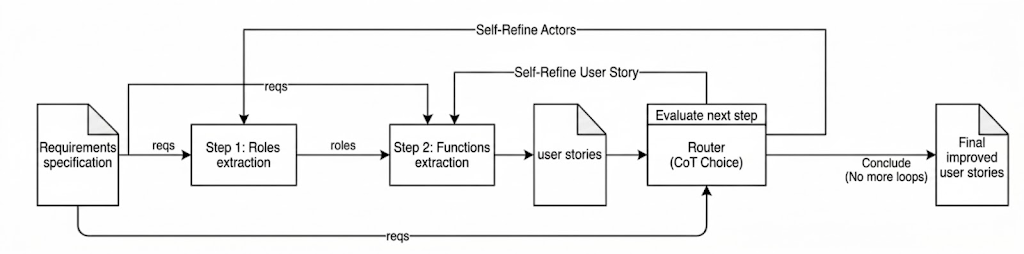

In [ ]:
# Router function: the objective of this code is to implement the node "Evaluate next step", which routers between three different paths

# ATTENTION: all the code below is designed to switch easily between human input and LLM choice in the router node. You can try both options to see the differences. For simplicity, in this solution we will use human input (_text_generation_pipeline = None)

from enum import Enum, auto
from typing import cast


class NextStep(Enum):
    REFINE_ACTORS = auto()
    REFINE_FUNCTIONS = auto()
    STOP = auto()

    def get_step_description(self) -> str:
        """For each possible value of the enum, returns a short description that teaches the model when the corresponding step should be chosen."""

        if self == NextStep.REFINE_ACTORS:
            return "Refine the list of actors."

        elif self == NextStep.REFINE_FUNCTIONS:
            return f"Refine the user stories defined for the actor \"{ROLE}\"."

        elif self == NextStep.STOP:
            return "There is not refinement needed."

        else:
            raise NotImplementedError
            return ""

    def get_step_prompt(self, _role: str = None) -> str:
        if self == NextStep.REFINE_ACTORS:
            raise NotImplementedError # TODO define a self-refinement prompt targeting the list of actors

        elif self == NextStep.REFINE_FUNCTIONS:
            raise NotImplementedError # TODO define a self-refinement prompt targeting the list of functions for the actor defined in the "ROLE" constant
        else:
            return ""

    @staticmethod
    def from_str(s: str) -> 'NextStep':
        if int(s) == NextStep.REFINE_ACTORS.value:
            return NextStep.REFINE_ACTORS
        elif int(s) == NextStep.REFINE_FUNCTIONS.value:
            return NextStep.REFINE_FUNCTIONS
        elif int(s) == NextStep.STOP.value:
            return NextStep.STOP
        else:
            raise ValueError("Unrecognized option")

    @staticmethod
    def get_choices():
        return ", ".join([f"\"{i.value}\"" for i in NextStep])

    @staticmethod
    def get_prompt_choices() -> str:
        raise NotImplementedError # TODO return a prompt that lists all the options


def force_choice(_messages: list[dict[str, str]], _text_generation_pipeline: TextGenerationPipeline = None) -> tuple[
    str | NextStep, bool]:
    """Function that implements a retry mechanism in order to force the model to choose an option between the ones listed in the NextStep enum.

    :param _text_generation_pipeline: If this object is not None, this function asks a model what is the next step, otherwise it takes it as input from the human user.

    :returns:A tuple composed by the final response and a flag that indicates if the response is valid."""
    max_retries = 5
    _messages_copy = list(_messages)

    for i in range(max_retries):
        if _text_generation_pipeline is not None:
            answer = _text_generation_pipeline(_messages_copy, max_new_tokens=1)[0]["generated_text"][-1]["content"]
        else:
            answer = input(_messages_copy[-1]["content"] if i > 0 else NextStep.get_prompt_choices())

        print(f"\n\n[Force choice ATTEMPT#{i}] response: {answer}")
        try:
            raise NotImplementedError # TODO verify that the "answer" is valid, and convert it into a NextStep object

            return option, True

        except ValueError:
            _messages_copy.append({'role': 'assistant', 'content': answer})
            _messages_copy.append({'role': 'user',
                                   'content': f""})     # TODO define a prompt that forces the human / LLM to provide a valid answer

    return answer, False


def router_gateway(_user_prompt: str, _text_generation_pipeline: TextGenerationPipeline = None, ) -> NextStep:
    _messages = [
        {'role': 'system',
         'content': f'Provide a valid answer between {NextStep.get_choices()}. Do not generate other text.'},
        {'role': 'user', 'content': _user_prompt}
    ]

    answer, valid = force_choice(_text_generation_pipeline=_text_generation_pipeline, _messages=_messages)

    if not valid:  # If it is impossible to obtain a valid response, just stop the process
        answer = NextStep.STOP

    else:
        print("Valid answer. Executing the step...")

    return cast(NextStep, answer)


In [ ]:
# Self-refinement loop: the objective of this code is to pack everything in a loop that allows the LLM to self-refine

MAX_ITERATIONS = 5

# The variables initialized here will be eventually updated by the self refinement loop
actors_self_refinement = re.split(r"[\n,]+", roles_extracted_few_shot)
user_stories_self_refinement = user_stories


def print_roles_stories():
    if type(actors_self_refinement) == list:
        _actors_str = ", ".join(actors_self_refinement)
    else:
        _actors_str = actors_self_refinement
    _user_stories_str = "\n".join(user_stories_self_refinement)
    print(
        f"## Roles: {_actors_str}\n\n## User stories for actor \"{ROLE}\":\n{_user_stories_str}")


i = 0
while True:

    if i >= MAX_ITERATIONS:  # This is needed only to avoid infinite loops in case the router node is fully automated via LLM
        print(f"Executed {MAX_ITERATIONS} iterations without completing self-refinement.")
        print_roles_stories()
        break
    i += 1

    print(f"[SELF-REFINEMENT LOOP#{i}]")
    print_roles_stories()

    # Choose the next step
    actors_list = ", ".join([a for a in actors_self_refinement])
    user_stories_list = "\n".join(user_stories_self_refinement)

    self_refinement_system_prompt = "" # TODO define a prompt that provides the LLM the necessary information to perform self-refinement, including personas and context (i.e., requirements specification, current identified roles, and current identified user stories for the target **ROLE**)

    next_step = router_gateway(_text_generation_pipeline=None,
                               # We pass a None object to use the human-in-the-loop approach
                               _user_prompt=self_refinement_system_prompt)

    # Execute the chosen action
    if next_step == NextStep.STOP:
        print(f"Process ended at step#{i}")
        print_roles_stories()
        break

    messages = [
        {'role': 'system', 'content': self_refinement_system_prompt},
        {'role': 'user', 'content': ""} # TODO prompt the model differently based on the selected next step
    ]
    _response = text_generation_pipeline(messages, max_new_tokens = 200)[0]["generated_text"][-1]["content"]

    if next_step == NextStep.REFINE_ACTORS:
        actors_self_refinement = "" # TODO replace with the last generated list

    elif next_step == NextStep.REFINE_FUNCTIONS:
        user_stories_self_refinement = "" # TODO replace with the last generated list (HINT: use the already-defined "extract_functions()" function)


### Question: Did the self-refinement improve the results?

Probably not. This is likely because the LLM needs a feedback guide to understand what to improve. We will experiment with this in the next lab... STAY TUNED!

## [OPTIONAL] Extracting the purposes

In this step, the focus is on extracting the purposes behind the functions identified in the previous step. The purpose refers to the underlying reasons or motivations that drive a role to perform a particular function within the system. The language model (LLM) is prompted to identify these reasons by analyzing the problem description and the functions extracted in the previous step.

After the functions (what the roles want to do) are identified, the LLM is tasked with understanding and extracting the why behind each function. For example, a role like "hiker" may want to "register for a hike" (function), but the purpose behind this action might be "so that they can track their progress" or "to ensure they can participate in the hike." Similarly, a "local guide" may want to "add a hike description," and the purpose could be "to provide helpful information to other users."

The extracted purposes help provide a deeper understanding of why each function is important to the roles. These purposes are essential for refining the system’s objectives and ensuring that the design aligns with the actual needs and motivations of the stakeholders. The LLM identifies these purposes by analyzing both the context of the roles and the corresponding functions, ensuring that all relevant purposes are captured to provide clarity for the user stories that will follow in the next step.

In [ ]:
# We take the pairs of role - function obtained in the previous step.
# For simplicity, we only consider one user story at this point.
# To complete the task, we would require to perform an iteration over all the stories defined - this would be very computationally expensive and is out of the scope of the current exercise.

user_story1 = user_stories[0]

system_prompt = "" # TODO define personas, task, and output format

# Few-shot

example1 = [
    {
        'role': 'user',
        'content': """**User Story (without purpose)**: "As a Customer, I want to browse the menu.
**Requirements Text**: "The application allows customers to browse menus and place orders from a variety of restaurants."""
    },

    {
        'role': 'assistant',
        'content': """As a Customer, I want to browse the menu, so that I can explore and select food items to place an order."""
    }
]

example2 = [
    {
        'role': 'user',
        'content': """**User Story (without purpose)**: "As a Teacher, I want to grade submissions."
**Requirements Text**: "Teachers can grade student submissions through the platform's grading tools."""
    },

    {
        'role': 'assistant',
        'content': """As a Teacher, I want to grade submissions, so that I can evaluate student performance and provide feedback."""
    }
]

example3 = [
    {
        'role': 'user',
        'content': """**User Story (without purpose)**: "As a Transit Operator, I want to manage timetables."
**Requirements Text**: "Transit operators can view and manage vehicle schedules, ensuring that vehicles adhere to the set timetables."""
    },

    {
        'role': 'assistant',
        'content': """As a Transit Operator, I want to manage timetables, so that I can ensure the vehicles run on time and provide reliable service.."""
    }
]

query = f"""""" # TODO ask the model to generate the purpose for the target user story

messages = [
    # TODO provide all the few-shot examples above
]

full_story = text_generation_pipeline(messages, max_new_tokens=2500)[0]["generated_text"][-1]["content"]
print(full_story)
